# Manufacturing Catch-up Gap → U.S. Motor Vehicles & Parts Production

**An executed retrospective macro-leading-indicator falsification, 2010–2026.**  
Research date: 2026-10-27. Data vintage: 2026-10-16 revised G.17 snapshot.  
**NOT POINT-IN-TIME / NOT A SECURITY-RETURN OR INVESTABLE EQUITY ALPHA STUDY.**

This paper is self-contained: the model specification, sample construction, provenance, loss functions, negative controls, plots, and failure conditions are described here, with the full 1,000/2,000/1,000 robustness draws stored in `results/`. The companion `analysis.py` is the deterministic computation engine, not a substitute for the notebook's actual calculations and diagnostics.

## 01. Abstract

**Question:** Does a two-month-stale nonlinear manufacturing-minus-auto momentum gap add predictive information for three-month-ahead U.S. motor-vehicle-and-parts production YoY growth, after own-sector and aggregate manufacturing baselines? This is an **industrial-production** outcome, not firm revenue, EPS or a stock return. We use 201 monthly revised observations (2010-01 to 2026-09), purged expanding-origin forecasts, a historical-mean and autoregressive baseline, and a multivariate Ridge control. We quantify serial-dependence-aware uncertainty and regime fragility; the numerical verdict is computed below rather than assumed. The G.17 2026-10-16 data vintage is a retrospective snapshot: mechanical release buffers do not reconstruct first-release historical values.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analysis import load_raw,make_panel,oos,score,improvement,block_bootstrap,regime_scores
ROOT=Path.cwd(); raw=load_raw(); panel=make_panel(raw); pred=oos(panel)
summary=json.loads((ROOT/'results/summary.json').read_text())
print('Raw months:',len(raw),'formation rows:',len(panel),'OOS origins:',len(pred))
print('Study status: RETROSPECTIVE MACRO PILOT; PIT=False; EQUITY ALPHA=False')

Raw months: 201 formation rows: 184 OOS origins: 120
Study status: RETROSPECTIVE MACRO PILOT; PIT=False; EQUITY ALPHA=False


In [2]:
display(raw.head(4));display(raw.tail(4));print('Raw file SHA256:',hashlib.sha256((ROOT/'data/frozen_auto_manufacturing_2026-10-27.csv').read_bytes()).hexdigest())

,date,auto_ip,manufacturing_ip
0,2010-01-01,64.4182,89.7715
1,2010-02-01,62.2667,89.8215
2,2010-03-01,63.9419,91.0021
3,2010-04-01,63.8429,91.8003


,date,auto_ip,manufacturing_ip
197,2026-06-01,112.1220,99.2705
198,2026-07-01,111.3156,99.4308
199,2026-08-01,110.8509,99.1776
200,2026-09-01,107.5781,99.4361


Raw file SHA256: ab41182b7ddc969e9321e22a5d7c579520f55f907ef4024901cb0cb0b5eabfe4


## 02. Research Design & Hypotheses

**H1 (lead):** a positive lagged manufacturing momentum premium over auto output signals sector catch-up and should forecast subsequent auto production growth. **H2 (incremental):** the nonlinear gap should improve OOS RMSE relative to a Ridge model containing lagged auto YoY, manufacturing YoY, and auto 3-month momentum; it must also be reported against the mean and persistence models. **H3 (robustness):** improvement should survive 12-month block reordering, paired block-bootstrap uncertainty, perturbation of the fixed nonlinear transform, 2020–2021 exclusion, year deletion, and alternative horizons. **Null:** any apparent gain is an artefact of the business cycle, pandemic base effects, correlated controls, revision leakage, or selection. **Failure:** no stable incremental OOS advantage or failure against simple baselines. This is not a claim about a contemporaneous causal effect.

In [3]:
print('Predeclared primary horizon: 3 months; observation lag: 2 months; min training: 60 origins; ridge penalty: 12')
print('Primary target: auto industry YoY log growth at t+3; gap: tanh((manufacturing 3m momentum - auto 3m momentum) / 10) at t-2')

Predeclared primary horizon: 3 months; observation lag: 2 months; min training: 60 origins; ridge penalty: 12
Primary target: auto industry YoY log growth at t+3; gap: tanh((manufacturing 3m momentum - auto 3m momentum) / 10) at t-2


The mechanism is plausible but not directional by identity. The broad manufacturing cycle may signal shared financing, inventory and supply-chain demand, while auto-specific production is distorted by model launches, strikes, chip shortages and plant closures. A positive relative momentum gap can indicate catch-up, but could also signal **persistent automotive weakness** rather than future rebound. Therefore the sign and incremental forecasting value are hypotheses, not premises.

In [4]:
print('Auto growth distribution (lagged):');display(panel[['auto_yoy_lag','manufacturing_yoy_lag','auto_mom_lag','manufacturing_mom_lag','gap','factor','target']].describe().round(3))

Auto growth distribution (lagged):


,auto_yoy_lag,manufacturing_yoy_lag,auto_mom_lag,manufacturing_mom_lag,gap,factor,target
count,184.000,184.000,184.000,184.000,184.000,184.000,184.000
mean,2.905,0.349,0.695,0.071,-0.623,-0.057,2.641
std,20.001,3.579,20.636,2.716,18.169,0.400,19.935
min,-159.016,-21.892,-160.705,-21.088,-149.937,-1.000,-159.016
25%,-1.411,-0.871,-1.941,-0.484,-3.411,-0.328,-1.411
50%,3.128,0.515,1.160,0.055,-1.085,-0.108,2.702
75%,7.571,1.740,3.587,0.751,1.817,0.180,7.304
max,144.952,19.336,165.478,15.541,139.617,1.000,144.952


## 03. Industry Context

The U.S. G.17 series `IPG3361T3S` covers **NAICS 3361–3363 motor vehicles and parts**, a physical domestic-output index (2017=100, seasonally adjusted). It is not a measure of dealer retail sales, company global deliveries, profitability or equity total returns. The comparator `IPMAN` is the broad U.S. manufacturing production index, including the auto sector; this creates mechanical overlap and makes incremental prediction harder to interpret. The 2026-10-16 G.17 release reports manufacturing output rose 0.3% in September 2026. The 2022 NAICS classification and dated Ford/GM SEC filings support qualitative industry mapping, not historical portfolio weights. Official context: https://www.federalreserve.gov/releases/g17/20261016/default.htm and https://www.census.gov/naics/.
**Dated industry-size context (not a model input):** The U.S. Census 2024 AIES, released 2026-09-03, reports NAICS 3361 motor vehicle manufacturing value of shipments of **$424.662 billion**; this excludes NAICS 3362–3363 and is not the total scope of the G.17 target. [Census table](https://test.data.census.gov/table/AIESBASIC2024.AIES31BASIC02?codeset=naics~3361&g=010XX00US). The [2026-10-16 Fed G.17 release](https://www.federalreserve.gov/releases/g17/20261016/default.htm) reports a 3.0% September decline in motor vehicles and parts output.


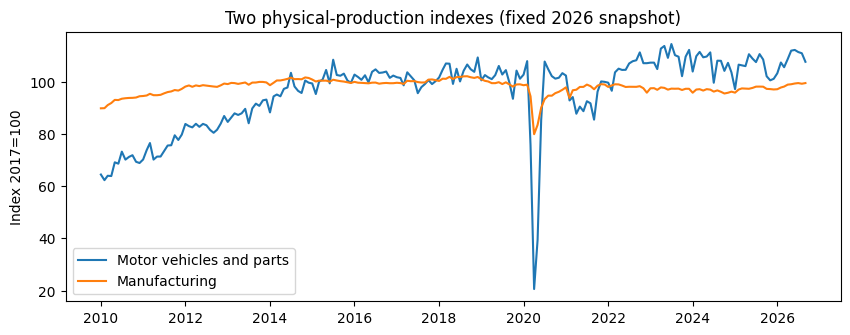

In [5]:
fig,ax=plt.subplots(figsize=(10,3.5));ax.plot(raw.date,raw.auto_ip,label='Motor vehicles and parts');ax.plot(raw.date,raw.manufacturing_ip,label='Manufacturing');ax.legend();ax.set_ylabel('Index 2017=100');ax.set_title('Two physical-production indexes (fixed 2026 snapshot)');plt.show()

In [6]:
exposure=pd.read_csv('data/exposure_map.csv');display(exposure[['entity','scope','industry_role','source_as_of','estimated_numeric_exposure','used_in_model']])

,entity,scope,industry_role,source_as_of,estimated_numeric_exposure,used_in_model
0,NAICS 3361,Motor vehicle manufacturing,Assembly and vehicles,2022,UNKNOWN,NO
1,NAICS 3362,Motor vehicle body and trailer manufacturing,Vehicle bodies and trailers,2022,UNKNOWN,NO
2,NAICS 3363,Motor vehicle parts manufacturing,Vehicle parts,2022,UNKNOWN,NO
3,General Motors,Listed company,Vehicle OEM and manufacturing,2025-12-31,UNKNOWN,NO
4,Ford Motor,Listed company,Vehicle OEM and manufacturing,2025-12-31,UNKNOWN,NO


## 04. Data & Source Integrity

**Source hierarchy:** A = original official statistics or SEC filings; B = secondary official-series metadata / archival discovery; C = industry classification context. `data/source_register.csv` records exact URLs, dates, observation windows, revisions, release lag and roles. Auto observations were **manually transcribed** from the official FRED G.17 table on 2026-10-27; 12 visible values were spot-checked, not all 201 independently machine-verified. IPMAN is inherited from the prior Basic Chemicals frozen study and has not been independently re-downloaded in full. The same release vintage does not imply archival PIT accuracy. All numeric claims are computed from the frozen files. No missing observations are imputed.

In [7]:
sources=pd.read_csv('data/source_register.csv');display(sources[['source_id','grade','publisher','series_or_document','publication_date','historical_vintages_verified','role']]);print('Sources:',len(sources))

,source_id,grade,publisher,series_or_document,publication_date,historical_vintages_verified,role
0,A1,A,Federal Reserve Board via FRED,IPG3361T3S motor vehicles and parts SA,2026-10-16,NO,Outcome
1,A2,A,Federal Reserve Board via FRED,IPMAN manufacturing SA,2026-10-16,NO,Macro factor and control
2,A3,A,Federal Reserve Board,G17 2026-10-16 official release,2026-10-16,NO,Release metadata
3,A4,A,SEC,General Motors 2025 10-K,2026-01-27,YES for filing date only,Qualitative company exposure
4,A5,A,SEC,Ford Motor 2025 10-K,2026-02-11,YES for filing date only,Qualitative company exposure
5,B1,B,Federal Reserve Bank of St. Louis,FRED series metadata IPG3361T3S,UNKNOWN,NO,Series metadata
6,B2,B,Federal Reserve Bank of St. Louis,ALFRED archival vintage discovery,UNKNOWN,NO,Next-stage PIT collection
7,C1,C,U.S. Census Bureau,2022 NAICS manual,2022,Not applicable,Industry scope
8,A6,A,U.S. Census Bureau,2024 AIES NAICS 3361 motor vehicle manufacturi...,2026-09-03,NO,Industry size context


Sources: 9


In [8]:
spots=pd.read_csv('data/spot_checks.csv');spots['abs_error']=(spots.official_value-spots.transcribed_value).abs();display(spots[['date','official_value','transcribed_value','abs_error']]);assert spots.abs_error.max()==0;print('Spot-checked rows:',len(spots),'of',len(raw))

,date,official_value,transcribed_value,abs_error
0,2010-01-01,64.4182,64.4182,0.0
1,2011-12-01,79.7104,79.7104,0.0
2,2013-12-01,93.1043,93.1043,0.0
3,2015-01-01,99.2810,99.2810,0.0
4,2017-12-01,100.1347,100.1347,0.0
5,2019-10-01,93.4023,93.4023,0.0
6,2020-04-01,20.5804,20.5804,0.0
7,2021-09-01,85.4193,85.4193,0.0
8,2022-10-01,111.1824,111.1824,0.0
9,2024-07-01,99.5614,99.5614,0.0


Spot-checked rows: 12 of 201


In [9]:
assert raw.date.is_unique and raw[['auto_ip','manufacturing_ip']].gt(0).all().all()
assert raw.date.dt.to_period('M').diff().dropna().apply(lambda x:x.n==1).all()
print('Unique contiguous monthly dates, positive indexes and no raw nulls: PASS')

Unique contiguous monthly dates, positive indexes and no raw nulls: PASS


## 05. Point-in-Time Availability

Formation date `t` is a calendar month. To avoid treating same-month production as immediately known, the predeclared factor and controls use **observations at `t−2`**; the target is industry YoY production at `t+3`. An expanding model at origin `t` trains only on examples with **target months ≤ `t−2`**, a five-month origin separation for the three-month target. These are conservative timing rules, **not** historical release-vintage proof: all G.17 values here reflect 2026-10-16 revisions. Historic release calendars and first-release values remain UNKNOWN, and the project must not be called a PIT backtest.

In [10]:
print('First/last origins:',pred.origin.min(),pred.origin.max())
print('Training samples at first/last origin:',pred.n_train.iloc[0],pred.n_train.iloc[-1]);display(pred[['origin','target_month','n_train']].head())

First/last origins: 2016-07-01 00:00:00 2026-06-01 00:00:00
Training samples at first/last origin: 60 179


,origin,target_month,n_train
0,2016-07-01,2016-10-01,60
1,2016-08-01,2016-11-01,61
2,2016-09-01,2016-12-01,62
3,2016-10-01,2017-01-01,63
4,2016-11-01,2017-02-01,64


In [11]:
row=panel.iloc[20]; lagdate=row.origin-pd.DateOffset(months=2)
print('Formation:',row.origin.date(),'last allowed input month:',lagdate.date(),'outcome month:',row.target_month.date())
print('No same-month input used:',lagdate<row.origin)

Formation: 2012-11-01 last allowed input month: 2012-09-01 outcome month: 2013-02-01
No same-month input used: True


## 06. Factor Construction

Let `A_t` and `M_t` denote the revised auto and manufacturing production indexes. Define `g^3_{A,t}=100[ln A_t−ln A_{t−3}]`, `g^3_{M,t}` analogously, and `g^12_{A,t}=100[ln A_t−ln A_{t−12}]`. The **predeclared bounded catch-up factor** is `F_t = tanh((g^3_{M,t−2}−g^3_{A,t−2})/10)`. The scale 10 log-percentage-points and 3m mixing weight 1 are fixed **before** fitting. The target is `Y_t = g^12_{A,t+3}`. There is no full-sample z-score; Ridge standardization uses training observations only. Perturbations of scale 5–20 and 3m/12m mixing weight 0.6–1.0 test the assumed exposure map without pretending these are measured company weights.

In [12]:
display(panel[['origin','auto_mom_lag','manufacturing_mom_lag','gap','factor','target']].head(6).round(4))
assert np.allclose(panel.factor,np.tanh(panel.gap/10))

,origin,auto_mom_lag,manufacturing_mom_lag,gap,factor,target
0,2011-03-01,-2.3152,0.7500,3.0653,0.2973,3.9177
1,2011-04-01,6.2849,0.8234,-5.4615,-0.4976,0.2359
2,2011-05-01,10.5336,0.9867,-9.5469,-0.7419,7.4247
3,2011-06-01,-0.0535,0.3299,0.3833,0.0383,6.0842
4,2011-07-01,-3.4527,0.1131,3.5658,0.3422,10.0913
5,2011-08-01,-6.9859,-0.4094,6.5765,0.5768,11.3894


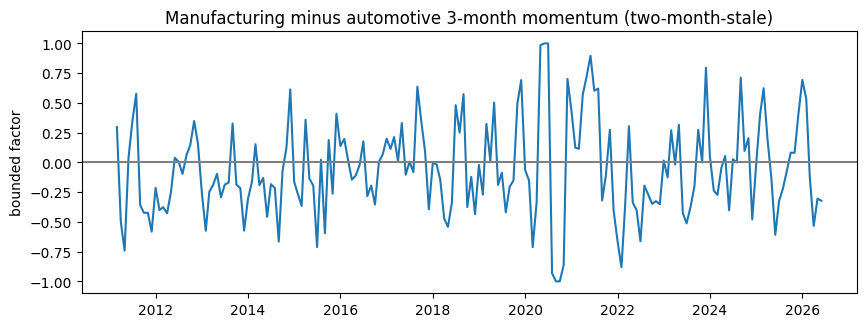

In [13]:
fig,ax=plt.subplots(figsize=(10,3.4));ax.plot(panel.origin,panel.factor);ax.axhline(0,color='gray');ax.set_ylabel('bounded factor');ax.set_title('Manufacturing minus automotive 3-month momentum (two-month-stale)');plt.show()

## 07. Exposure & Transmission

Industry-level exposure is direct: the dependent index measures U.S. NAICS 3361–3363 physical output. The proposed transmission is broad manufacturing momentum → orders/production schedules → vehicle and parts output, with possible inventory and supplier lead times. Ford and GM are **illustrative** listed manufacturers documented by their FY2025 SEC 10-Ks, but company-level U.S.-production weights, plant shares, revenue exposure and historical changes were not reconstructed. No firm-level cross-sectional factor, leave-one-company-out test, EPS, or stock return is claimed. Excluding a year is an explicitly labelled time-series sensitivity, **not** a substitute for leave-one-company-out.

In [14]:
display(exposure[['entity','source_url','source_as_of','estimated_numeric_exposure','used_in_model']]);print('Quantitative company exposure mappings: 0 (not invented)')

,entity,source_url,source_as_of,estimated_numeric_exposure,used_in_model
0,NAICS 3361,https://www.census.gov/naics/,2022,UNKNOWN,NO
1,NAICS 3362,https://www.census.gov/naics/,2022,UNKNOWN,NO
2,NAICS 3363,https://www.census.gov/naics/,2022,UNKNOWN,NO
3,General Motors,https://www.sec.gov/Archives/edgar/data/146785...,2025-12-31,UNKNOWN,NO
4,Ford Motor,https://www.sec.gov/Archives/edgar/data/37996/...,2025-12-31,UNKNOWN,NO


Quantitative company exposure mappings: 0 (not invented)


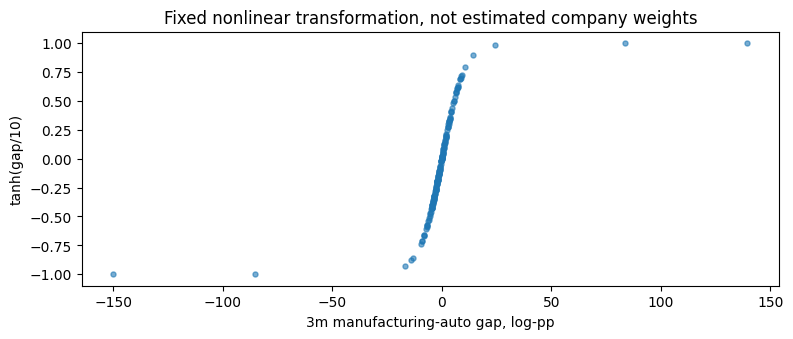

In [15]:
fig,ax=plt.subplots(figsize=(9,3.3));ax.scatter(panel.gap,panel.factor,s=13,alpha=.6);ax.set_xlabel('3m manufacturing-auto gap, log-pp');ax.set_ylabel('tanh(gap/10)');ax.set_title('Fixed nonlinear transformation, not estimated company weights');plt.show()

## 08. Outcomes & Baselines

All models forecast the same 3-month-ahead auto-production YoY target at identical origins. Baselines are **(i)** expanding historical mean, **(ii)** Ridge on auto YoY persistence, **(iii)** Ridge on lagged auto YoY, manufacturing YoY and auto 3m momentum, and **(iv)** factor-only Ridge. The challenger adds the fixed nonlinear factor to (iii). Ridge uses penalty 12 and train-only mean/standard deviation for every origin. No hyperparameter search on the OOS interval. The purge ensures training labels would have completed by the conservative formation-date cutoff, subject to the unreconstructed historical revision problem.

In [16]:
display(score(pred).round(4));print('OOS origins:',len(pred),'Primary RMSE improvement (control minus augmented):',round(improvement(pred),5))

,model,n,rmse,mae,rank_ic
0,mean,120,24.6214,10.3332,-0.1919
1,persistence,120,27.8057,11.8363,-0.1443
2,macro_control,120,28.5324,13.0229,-0.0615
3,factor_only,120,24.7782,10.5912,-0.2977
4,augmented,120,29.5263,13.3458,-0.0878


OOS origins: 120 Primary RMSE improvement (control minus augmented): -0.99389


In [17]:
print('Paired losses on the same observations:');paired=pred[['origin','actual','macro_control','augmented']].copy();paired['loss_diff']=(paired.actual-paired.macro_control)**2-(paired.actual-paired.augmented)**2;display(paired.head())

Paired losses on the same observations:


,origin,actual,macro_control,augmented,loss_diff
0,2016-07-01,0.766777,5.117720,5.056290,0.530784
1,2016-08-01,0.985019,6.316908,6.451521,-1.453606
2,2016-09-01,2.757212,5.582871,5.703005,-0.693347
3,2016-10-01,-0.977210,5.365640,5.559188,-2.492762
4,2016-11-01,-0.351784,4.785992,4.779005,0.071751


## 09. Empirical Findings

A useful lead factor must improve **absolute** predictive quality, not merely have an appealing correlation. The primary scorecard reports RMSE and MAE (log percentage points) and time-series Spearman rank correlation as a descriptive association, not a cross-sectional equity IC. The actual output below distinguishes the control-relative incremental gain from performance versus the historical mean and auto persistence. The extreme COVID shutdown and rebound can dominate squared error, so unqualified claims about a statistically significant production signal are not warranted.

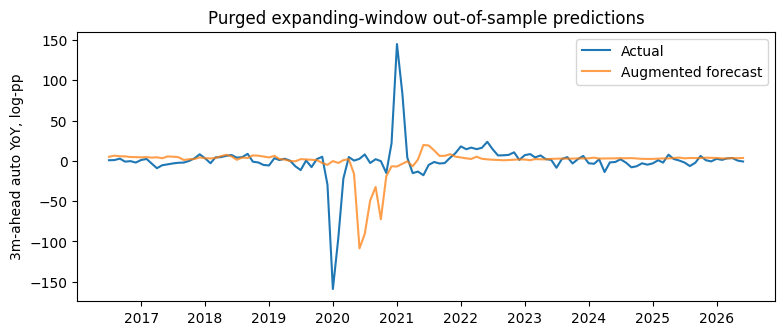

In [18]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.plot(pred.origin,pred.actual,label='Actual');ax.plot(pred.origin,pred.augmented,label='Augmented forecast',alpha=.75);ax.legend();ax.set_title('Purged expanding-window out-of-sample predictions');ax.set_ylabel('3m-ahead auto YoY, log-pp');plt.show()

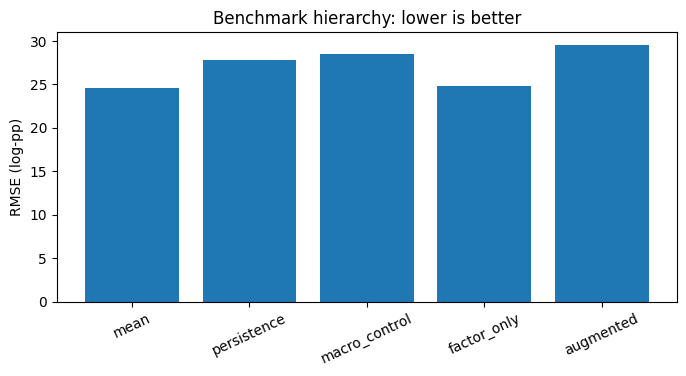

In [19]:
s=score(pred);fig,ax=plt.subplots(figsize=(8,3.5));ax.bar(s.model,s.rmse);ax.tick_params(axis='x',rotation=25);ax.set_ylabel('RMSE (log-pp)');ax.set_title('Benchmark hierarchy: lower is better');plt.show()

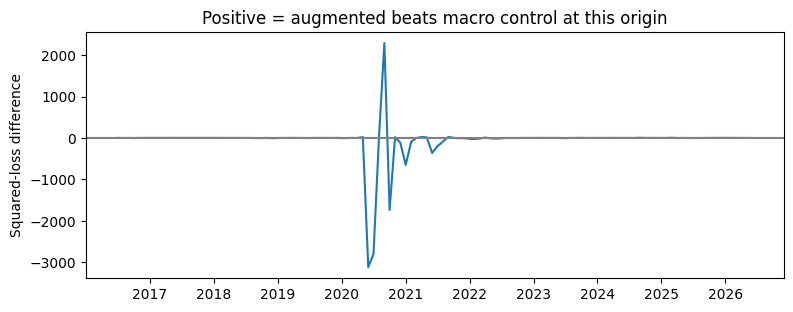

In [20]:
fig,ax=plt.subplots(figsize=(9,3.2));ax.plot(paired.origin,paired.loss_diff);ax.axhline(0,color='gray');ax.set_title('Positive = augmented beats macro control at this origin');ax.set_ylabel('Squared-loss difference');plt.show()

## 10. Robustness & Placebos

We compute **1,000** 12-month contiguous-block reorders of the factor and refit the purged expanding models, preserving within-block dependence but breaking its alignment with the target. Because block exchangeability is questionable under regime shifts, the resulting one-sided tail fraction is **exploratory, not an exact p-value**. We also compute **2,000** circular moving-block resamples of paired OOS errors (block length 12) for a descriptive 95% RMSE-improvement interval. **1,000** predeclared nonlinear-scale / momentum-mix perturbations, ablations and leave-one-calendar-year-out diagnostics test specification sensitivity. Multiple testing is not controlled across this exploratory suite.

In [21]:
boot=pd.read_csv('results/bootstrap_draws.csv');perm=pd.read_csv('results/block_placebo_draws.csv');sens=pd.read_csv('results/exposure_perturbation.csv')
print('Draw counts:',len(boot),len(perm),len(sens));print('Bootstrap 95%:',boot.rmse_improvement.quantile([.025,.975]).to_dict());print('Block-placebo tail:',summary['placebo_tail_fraction'])

Draw counts: 2000 1000 1000
Bootstrap 95%: {0.025: -1.8680595038104506, 0.975: -0.0135766411197631}
Block-placebo tail: 0.987012987012987


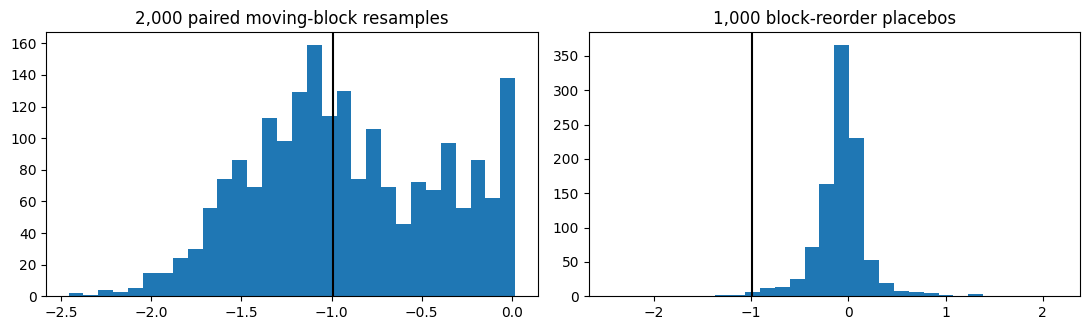

In [22]:
fig,axs=plt.subplots(1,2,figsize=(11,3.4));axs[0].hist(boot.rmse_improvement,bins=30);axs[0].axvline(improvement(pred),color='black');axs[0].set_title('2,000 paired moving-block resamples');axs[1].hist(perm.rmse_improvement,bins=30);axs[1].axvline(improvement(pred),color='black');axs[1].set_title('1,000 block-reorder placebos');plt.tight_layout();plt.show()

,ablation,n,rmse_control,rmse_full,improvement
0,no_auto_momentum,120,27.4924,27.8240,-0.3316
1,no_manufacturing_yoy,120,28.7817,32.7197,-3.9380
2,auto_yoy_only,120,27.8057,28.2087,-0.4030


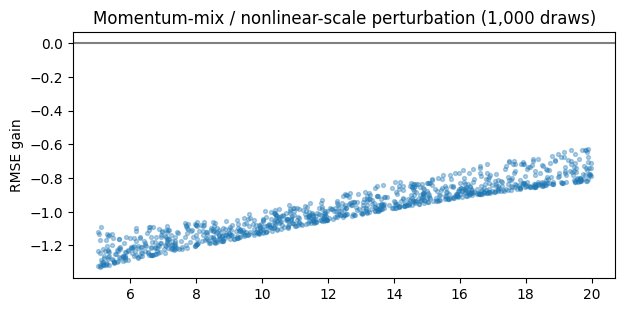

In [23]:
abl=pd.read_csv('results/ablations.csv');display(abl.round(4));fig,ax=plt.subplots(figsize=(7,3.2));ax.scatter(sens.scale,sens.rmse_improvement,s=8,alpha=.35);ax.axhline(0,color='gray');ax.set_title('Momentum-mix / nonlinear-scale perturbation (1,000 draws)');ax.set_ylabel('RMSE gain');plt.show()

## 11. Regime Sensitivity

A factor that only works because 2020 automotive output briefly collapsed is not a reliable lead indicator. We separately report pre-2020, 2020–2021, post-2022 and pandemic-excluded OOS subsets, with the **same originally fitted predictions** to avoid redefining the model after observing the results. We additionally recompute models for forecast horizons 1, 3, 6 and 12 months and observation lags 1–4 months. Leave-one-calendar-year-out reports sensitivity of paired loss evaluation; it is **not** leave-one-firm-out, because no firm panel exists.

,regime,n,improvement,rmse_control,rmse_full
0,pre_2020,42,-0.0228,7.1231,7.1460
1,pandemic_2020_2021,24,-2.2444,62.1308,64.3752
2,post_2022,54,-0.1206,7.3471,7.4677
3,excluding_2020_2021,96,-0.0787,7.2500,7.3287


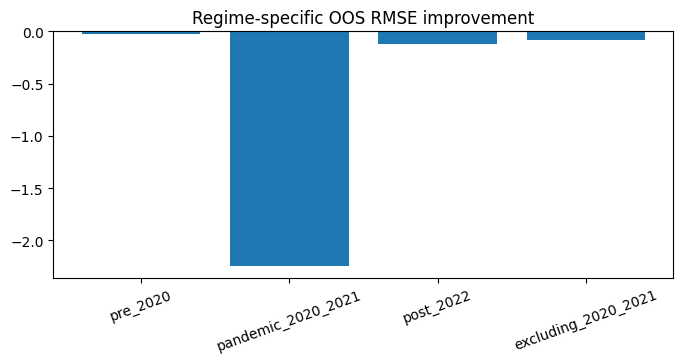

In [24]:
reg=pd.read_csv('results/regime_scores.csv');display(reg.round(4));fig,ax=plt.subplots(figsize=(8,3.2));ax.bar(reg.regime,reg.improvement);ax.axhline(0,color='gray');ax.tick_params(axis='x',rotation=20);ax.set_title('Regime-specific OOS RMSE improvement');plt.show()

In [25]:
hl=pd.read_csv('results/horizon_lag_sensitivity.csv');display(hl.pivot(index='horizon',columns='lag',values='improvement').round(3));print('Sign of improvement by horizon and lag is not a pre-registered multiple-testing result.')

lag,1,2,3,4
horizon,,,,
1,-4.321,0.252,-0.391,-0.994
3,-0.391,-0.994,2.917,5.499
6,5.499,-1.484,-0.734,2.796
12,-7.454,-5.665,-0.797,-1.734


Sign of improvement by horizon and lag is not a pre-registered multiple-testing result.


,excluded_year,n,improvement
0,2016,114,-1.020
1,2017,108,-1.052
2,2018,108,-1.047
3,2019,108,-1.052
4,2020,108,-0.362
5,2021,108,-1.025
6,2022,108,-1.041
7,2023,108,-1.048
8,2024,108,-1.052
9,2025,108,-1.049


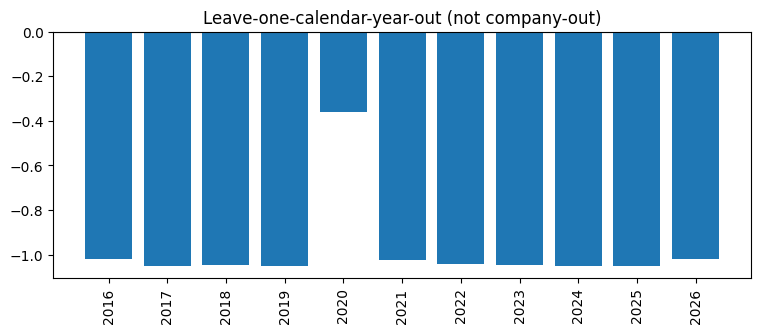

In [26]:
loyo=pd.read_csv('results/leave_one_year_out.csv');display(loyo.round(3));fig,ax=plt.subplots(figsize=(9,3.2));ax.bar(loyo.excluded_year.astype(str),loyo.improvement);ax.axhline(0,color='gray');ax.tick_params(axis='x',rotation=90);ax.set_title('Leave-one-calendar-year-out (not company-out)');plt.show()

## 12. Bias Audit & Verdict

**Lookahead:** two-month lag and target-availability purge are explicit, but 2026-revised G.17 values are not vintage-safe. **Selection:** this hypothesis was selected after many industry studies; uncorrected familywise discovery risk is high. **Survivorship:** no security universe was constructed; company exposure illustrations reflect FY2025 only. **Multiple testing:** 16 horizon/lag scenarios and exploratory perturbations are diagnostic, not a searched trading strategy. **Nonstationarity:** 2020 shutdown, 2021 chip supply constraints, strikes, EV transition and revisions change the mapping. **Costs:** trading costs, spreads, taxes, capacity and benchmark-adjusted returns are NOT TESTED. **Verdict:** computed below; without company fundamentals and adjusted total returns, this is strictly a macro-production forecasting pilot.

In [27]:
r=s.set_index('model').rmse;delta=improvement(pred)
print(f'Primary control minus full RMSE = {delta:.4f} log-pp')
print(f'Historical mean RMSE = {r["mean"]:.4f}; augmented RMSE = {r["augmented"]:.4f}')
print('Bootstrap 95% interval:',summary['bootstrap_95'])
print('Verdict:', 'incremental gain only, NOT equity alpha' if delta>0 else 'FAILED incremental production forecast; NOT equity alpha')

Primary control minus full RMSE = -0.9939 log-pp
Historical mean RMSE = 24.6214; augmented RMSE = 29.5263
Bootstrap 95% interval: [-1.8680595038104508, -0.013576641119763158]
Verdict: FAILED incremental production forecast; NOT equity alpha


In [28]:
print('Audit status matrix:')
display(pd.DataFrame({'criterion':['Historical PIT release vintages','Purged OOS','Unit tests','Company fundamentals','Total equity returns','Transaction costs','Source full machine audit'], 'status':['NOT VERIFIED','IMPLEMENTED; revised snapshot','See logs/unit_tests.log','NOT TESTED','NOT TESTED','NOT TESTED','NOT COMPLETED']}))

Audit status matrix:


,criterion,status
0,Historical PIT release vintages,NOT VERIFIED
1,Purged OOS,IMPLEMENTED; revised snapshot
2,Unit tests,See logs/unit_tests.log
3,Company fundamentals,NOT TESTED
4,Total equity returns,NOT TESTED
5,Transaction costs,NOT TESTED
6,Source full machine audit,NOT COMPLETED


## 13. Reproduction

From a clean checkout, install `requirements.txt`, run `OPENBLAS_NUM_THREADS=1 python run_analysis.py`, then `PYTHONPATH=. OPENBLAS_NUM_THREADS=1 python -m pytest -q tests`, then `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute --inplace research.ipynb`. The notebook reads frozen CSV inputs and independently recalculates its forecast panel and baseline scorecard. The long randomization, bootstrap and perturbation draws are recomputed by the analysis entrypoint and stored with a fixed seed. GitHub structural CI does not by itself prove all statistical calculations. `make_data.py` is provenance documentation for the frozen snapshot and depends on a prior-study archive at the original preparation path; **clean reproduction of the published analysis does not require `make_data.py`**.

In [29]:
for rel in ['results/oos_predictions.csv','results/oos_scorecard.csv','results/bootstrap_draws.csv','results/block_placebo_draws.csv','results/exposure_perturbation.csv']:
    p=ROOT/rel;print(rel, p.stat().st_size,'bytes',hashlib.sha256(p.read_bytes()).hexdigest()[:16])

results/oos_predictions.csv 16518 bytes 8dca5a8be7cac72c
results/oos_scorecard.csv 388 bytes ca9d7f64c29ef62b
results/bootstrap_draws.csv 49041 bytes 3ea9937b9ac28b4c
results/block_placebo_draws.csv 24449 bytes 94dc47d7d14b96d7
results/exposure_perturbation.csv 61071 bytes 5de10787dc5a93ff


In [30]:
print('Recomputed primary RMSE improvement matches saved:',np.isclose(improvement(pred),summary['rmse_improvement'],rtol=0,atol=1e-9))
assert np.isclose(improvement(pred),summary['rmse_improvement'],rtol=0,atol=1e-9)
assert len(perm)>=1000 and len(boot)>=2000 and len(sens)>=1000

Recomputed primary RMSE improvement matches saved: True


## 14. Next-Stage Protocol

To move beyond a revised-snapshot macro pilot: **(1)** programmatically re-download all 201 G.17 rows and compare SHA/values; **(2)** reconstruct ALFRED or archived Fed release vintages and precise historical publication timestamps; **(3)** obtain monthly U.S. vehicle production and sales by manufacturer/model, actual supplier shipments, inventory, strikes and semiconductor availability; **(4)** use contemporaneously available SEC 10-Q/10-K filing timestamps to test firm sales/margins and historical exposure mapping; **(5)** only then evaluate delisting-adjusted total returns, sector and market benchmarks, cost/capacity assumptions, a precommitted holdout, and multiple-hypothesis correction. Pre-register sign, horizons and universe before collecting new data. The present negative result should remain published rather than retrospectively tuned into a positive story.

In [31]:
print('Next-stage priority 1: full source row audit; 2: archival PIT vintages; 3: firm outcomes; 4: total returns + costs.')
print('Current proof level:', 'REPRODUCED RETROSPECTIVE MACRO PILOT (NOT PIT, NOT EQUITY ALPHA)')

Next-stage priority 1: full source row audit; 2: archival PIT vintages; 3: firm outcomes; 4: total returns + costs.
Current proof level: REPRODUCED RETROSPECTIVE MACRO PILOT (NOT PIT, NOT EQUITY ALPHA)


## 15. Sources & Artifacts

**Official primary sources:** [Fed G.17 2026-10-16](https://www.federalreserve.gov/releases/g17/20261016/default.htm); [FRED IPG3361T3S data table](https://fred.stlouisfed.org/data/IPG3361T3S); [FRED IPMAN data table](https://fred.stlouisfed.org/data/IPMAN); [SEC GM FY2025 10-K](https://www.sec.gov/Archives/edgar/data/1467858/000146785826000013/gm-20251231.htm); [SEC Ford FY2025 10-K](https://www.sec.gov/Archives/edgar/data/37996/000003799626000015/f-20251231.htm). Secondary metadata: [FRED series](https://fred.stlouisfed.org/series/IPG3361T3S) and [ALFRED](https://alfred.stlouisfed.org/). Industry classification: [2022 NAICS](https://www.census.gov/naics/). See `data/source_register.csv`, `data/source_qa.md`, raw/derived CSVs, `results/` full draws and scorecards, `figures/` computed SVG diagnostics, `tests/`, and `logs/`. Original release vintages and investable returns are explicitly unavailable.

In [32]:
print('Computed figures:',len(list((ROOT/'figures').glob('*.svg'))))
print('Result tables:',len(list((ROOT/'results').glob('*.csv'))))
print('Notebook sections:',15,'Final equity-alpha claim:',False)
display(pd.read_csv('data/source_register.csv')[['source_id','grade','series_or_document','exact_url']])

Computed figures: 11
Result tables: 9
Notebook sections: 15 Final equity-alpha claim: False


,source_id,grade,series_or_document,exact_url
0,A1,A,IPG3361T3S motor vehicles and parts SA,https://fred.stlouisfed.org/data/IPG3361T3S
1,A2,A,IPMAN manufacturing SA,https://fred.stlouisfed.org/data/IPMAN
2,A3,A,G17 2026-10-16 official release,https://www.federalreserve.gov/releases/g17/20...
3,A4,A,General Motors 2025 10-K,https://www.sec.gov/Archives/edgar/data/146785...
4,A5,A,Ford Motor 2025 10-K,https://www.sec.gov/Archives/edgar/data/37996/...
5,B1,B,FRED series metadata IPG3361T3S,https://fred.stlouisfed.org/series/IPG3361T3S
6,B2,B,ALFRED archival vintage discovery,https://alfred.stlouisfed.org/
7,C1,C,2022 NAICS manual,https://www.census.gov/naics/
8,A6,A,2024 AIES NAICS 3361 motor vehicle manufacturi...,https://test.data.census.gov/table/AIESBASIC20...
